# Notebook 1 — Baseline Risk Model (WiDS 2020 → XGBoost + SHAP + Equalized-Odds Audit)

**Role in the pipeline.** This model runs **once per patient at t = 0**. It answers: *"for a person with this background, what is the typical in-hospital mortality risk?"*
Its calibrated probability `p_base` is the anchor of the composite score; the time-series and imaging models later adjust it in log-odds.

**Design decisions implemented here**
- **Background features only** (demographics, comorbidities, admission source/type, diagnosis group). First-24h vitals, labs and APACHE physiology are excluded so the same signal is not counted twice when the time-series model adjusts the baseline.
- **Race/ethnicity is never a model input.** It is used only for the fairness audit.
- **Probability stays unconstrained.** `p_base` comes from the calibrated XGBoost. Equalized odds is applied **only to the binary death/no-death flag** (Fairlearn `ThresholdOptimizer`), and gaps are reported before and after.
- **Brier skill score** (vs. predicting the training base rate) is saved for use as a reliability weight.

**Inputs:** WiDS Datathon 2020 competition (`training_v2.csv`, optionally `WiDS Datathon 2020 Dictionary.csv`).

**Outputs (`/kaggle/working/artifacts_xgboost/` + a zip of it):** preprocessor, XGBoost model, Platt calibrator, equalized-odds post-processor, `xgb_inference.py` loader module, metrics, fairness tables, SHAP importance, test-set patients for the demo, plots.

## 1. Setup

In [1]:
!pip install -q fairlearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.4/141.4 kB 2.6 MB/s eta 0:00:00a 0:00:01


In [2]:
import os, sys, glob, json, shutil, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

SEED = 42
np.random.seed(SEED)

# ---- paths --------------------------------------------------------------
def find_file(name, required=True):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    if hits:
        return hits[0]
    local = os.path.join(os.environ.get("WIDS_DIR", "."), name)   # for running outside Kaggle
    if os.path.exists(local):
        return local
    if required:
        raise FileNotFoundError(f"{name} not found. Add the 'WiDS Datathon 2020' competition as an input.")
    return None

DATA_CSV = find_file("training_v2.csv")
DICT_CSV = find_file("WiDS Datathon 2020 Dictionary.csv", required=False)

WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath(".")
OUT_DIR  = os.path.join(WORK_DIR, "artifacts_xgboost")
PLOT_DIR = os.path.join(OUT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

# ---- experiment settings -------------------------------------------------
VAL_FRAC, TEST_FRAC = 0.15, 0.15
MIN_DEATHS_FOR_EO_GROUP = 15   # groups with fewer deaths in validation are merged into "Other/Unknown" for the post-processor
MIN_DEATHS_REPORT       = 30   # groups with fewer test deaths are flagged as low-support in the audit

print("data   :", DATA_CSV)
print("dict   :", DICT_CSV)
print("output :", OUT_DIR)

data   : /kaggle/input/competitions/widsdatathon2020/training_v2.csv
dict   : /kaggle/input/competitions/widsdatathon2020/WiDS Datathon 2020 Dictionary.csv
output : /kaggle/working/artifacts_xgboost


## 2. Shared inference module
Everything that must behave **identically at training time and in Notebook 4** (feature lists, input cleaning, calibration wrapper, artifact loader, SHAP explanation) lives in one file saved with the artifacts. The notebook imports it from there, so pickled objects reference `xgb_inference` and load cleanly later.

In [3]:
%%writefile {OUT_DIR}/xgb_inference.py
"""Baseline (background) mortality-risk model: shared code for training (NB1) and inference (NB4).

Usage in a later notebook:
    import sys; sys.path.insert(0, "/kaggle/input/<your-artifacts-dataset>/artifacts_xgboost")
    from xgb_inference import BaselineRiskModel
    base = BaselineRiskModel("/kaggle/input/<your-artifacts-dataset>/artifacts_xgboost")
    p_base = base.predict_base(patient_df)          # calibrated probability, unconstrained
    expl   = base.explain(patient_df.iloc[[0]])     # per-feature SHAP (log-odds of the raw model)
    flag   = base.fair_decision(patient_df)         # equalized-odds binary flag (needs 'ethnicity' column)
"""
import json
import os

import joblib
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin

TARGET = "hospital_death"
ID_COL = "encounter_id"
PROTECTED = "ethnicity"          # audit only, never a model input

NUMERIC = ["age", "bmi", "height", "weight", "pre_icu_los_days"]
BINARY = [
    "elective_surgery", "aids", "cirrhosis", "diabetes_mellitus", "hepatic_failure",
    "immunosuppression", "leukemia", "lymphoma", "solid_tumor_with_metastasis",
]
CATEGORICAL = [
    "gender", "hospital_admit_source", "icu_admit_source", "icu_stay_type",
    "icu_type", "apache_3j_bodysystem",
]
FEATURES = NUMERIC + BINARY + CATEGORICAL

EXCLUDED_ON_PURPOSE = {
    "ethnicity": "protected attribute - fairness audit only",
    "hospital_id, icu_id": "site identifiers - strong proxies, no clinical meaning",
    "d1_*, h1_* (vitals/labs)": "acute physiology - handled by the time-series model (avoid double counting)",
    "apache_*_score, *_apache physiology, gcs_*, ventilated/intubated": "acute severity - same reason",
    "apache_4a_hospital/icu_death_prob": "outcome-model output - leakage",
    "apache_3j_diagnosis, apache_2_diagnosis (codes)": "replaced by the coarser diagnosis group apache_3j_bodysystem",
    "apache_2_bodysystem": "redundant with apache_3j_bodysystem",
    "readmission_status": "constant in WiDS",
}


def logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    return np.log(p / (1 - p))


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=float)))


def prepare_frame(df):
    """Select and clean the background features (identical at train and inference time)."""
    out = df.reindex(columns=FEATURES).copy()
    for c in NUMERIC + BINARY:
        out[c] = pd.to_numeric(out[c], errors="coerce")
    out["pre_icu_los_days"] = out["pre_icu_los_days"].clip(lower=0)
    for c in CATEGORICAL:
        out[c] = out[c].astype("object").where(out[c].notna(), np.nan)
    return out


def map_audit_groups(ethnicity, group_map):
    s = pd.Series(ethnicity).astype("object").fillna("Unknown").astype(str)
    return s.map(lambda v: group_map.get(v, "Other/Unknown")).to_numpy()


class CalibratedXGB(BaseEstimator, ClassifierMixin):
    """XGBoost + Platt scaling on the raw logit: p = sigmoid(a * logit(p_raw) + b)."""

    def __init__(self, model=None, a=1.0, b=0.0):
        self.model = model
        self.a = a
        self.b = b

    def fit(self, X=None, y=None):           # model is pre-fitted; this only marks the wrapper as fitted
        self.classes_ = np.array([0, 1])
        return self

    def raw_proba(self, X):
        return self.model.predict_proba(X)[:, 1]

    def predict_proba(self, X):
        p = sigmoid(self.a * logit(self.raw_proba(X)) + self.b)
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)


class BaselineRiskModel:
    """Loads every Notebook-1 artifact from one folder."""

    def __init__(self, art_dir):
        import xgboost as xgb
        self.art_dir = art_dir
        self.cfg = json.load(open(os.path.join(art_dir, "feature_config.json")))
        self.metrics = json.load(open(os.path.join(art_dir, "metrics.json")))
        self.preproc = joblib.load(os.path.join(art_dir, "preprocessor.joblib"))
        booster_model = xgb.XGBClassifier()
        booster_model.load_model(os.path.join(art_dir, "xgb_model.json"))
        cal = json.load(open(os.path.join(art_dir, "calibrator.json")))
        self.clf = CalibratedXGB(booster_model, cal["a"], cal["b"]).fit()
        self.base_rate = self.metrics["base_rate_train"]
        self.bss = self.metrics["test"]["calibrated"]["brier_skill_score"]
        self.threshold = self.metrics["decision_threshold"]
        self.group_map = json.load(open(os.path.join(art_dir, "audit_group_map.json")))
        eo_path = os.path.join(art_dir, "eq_odds_postprocessor.joblib")
        self.eo = joblib.load(eo_path) if os.path.exists(eo_path) else None

    def transform(self, df):
        return self.preproc.transform(prepare_frame(df))

    def predict_base(self, df):
        """Calibrated, unconstrained in-hospital death probability (p_base)."""
        return self.clf.predict_proba(self.transform(df))[:, 1]

    def explain(self, df_row, top_k=8):
        """SHAP values (raw-model log-odds) for ONE patient, aggregated back to the original features."""
        import xgboost as xgb
        X = self.transform(df_row.iloc[[0]] if len(df_row) > 1 else df_row)
        contrib = self.clf.model.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)[0]
        enc = pd.Series(contrib[:-1], index=X.columns)
        agg = {}
        for col, val in enc.items():
            orig = self.cfg["encoded_to_original"].get(col, col)
            agg[orig] = agg.get(orig, 0.0) + float(val)
        raw = prepare_frame(df_row).iloc[0]
        out = pd.DataFrame({"feature": list(agg), "shap": list(agg.values())})
        out["value"] = out["feature"].map(lambda f: raw.get(f, np.nan))
        out = out.reindex(out["shap"].abs().sort_values(ascending=False).index).head(top_k)
        return out.reset_index(drop=True), float(contrib[-1])   # (top features, expected log-odds)

    def fair_decision(self, df, random_state=0):
        """Equalized-odds binary flag. Needs the 'ethnicity' column (group membership is required by
        post-processing; it never enters the probability model)."""
        if self.eo is None:
            raise RuntimeError("No equalized-odds post-processor saved.")
        groups = map_audit_groups(df[PROTECTED], self.group_map)
        return self.eo.predict(self.transform(df), sensitive_features=groups, random_state=random_state)

Writing /kaggle/working/artifacts_xgboost/xgb_inference.py


In [4]:
sys.dont_write_bytecode = True          # keep __pycache__ out of the artifacts folder
sys.path.insert(0, OUT_DIR)
import importlib, xgb_inference
importlib.reload(xgb_inference)
from xgb_inference import (TARGET, ID_COL, PROTECTED, NUMERIC, BINARY, CATEGORICAL, FEATURES,
                           EXCLUDED_ON_PURPOSE, logit, sigmoid, prepare_frame, map_audit_groups, CalibratedXGB)
print(len(FEATURES), "background features:", FEATURES)

20 background features: ['age', 'bmi', 'height', 'weight', 'pre_icu_los_days', 'elective_surgery', 'aids', 'cirrhosis', 'diabetes_mellitus', 'hepatic_failure', 'immunosuppression', 'leukemia', 'lymphoma', 'solid_tumor_with_metastasis', 'gender', 'hospital_admit_source', 'icu_admit_source', 'icu_stay_type', 'icu_type', 'apache_3j_bodysystem']


## 3. Load data and sanity checks

In [5]:
df = pd.read_csv(DATA_CSV)
print("raw shape:", df.shape)

needed = FEATURES + [TARGET, PROTECTED, ID_COL]
missing = [c for c in needed if c not in df.columns]
assert not missing, f"missing columns: {missing}"

df = df[df[TARGET].notna()].reset_index(drop=True)
df[TARGET] = df[TARGET].astype(int)
df["ethnicity_raw"] = df[PROTECTED].astype("object").fillna("Unknown").astype(str)
df["sex_group"]     = df["gender"].astype("object").fillna("Unknown").astype(str)
df["age_band"]      = pd.cut(df["age"], [0, 40, 60, 75, 200], labels=["<40", "40-59", "60-74", "75+"],
                             right=False).astype("object").fillna("Unknown")

print("rows with label:", len(df), "| in-hospital death rate: %.3f" % df[TARGET].mean())
print("\nfeature missingness (%):")
print((df[FEATURES].isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

raw shape: (91713, 186)
rows with label: 91713 | in-hospital death rate: 0.086

feature missingness (%):
hospital_admit_source          23.3
age                             4.6
bmi                             3.7
weight                          3.0
apache_3j_bodysystem            1.8
height                          1.5
cirrhosis                       0.8
aids                            0.8
immunosuppression               0.8
leukemia                        0.8
hepatic_failure                 0.8
diabetes_mellitus               0.8
solid_tumor_with_metastasis     0.8
lymphoma                        0.8
icu_admit_source                0.1
pre_icu_los_days                0.0
elective_surgery                0.0
gender                          0.0
icu_stay_type                   0.0
icu_type                        0.0


In [6]:
# Descriptions of the selected features (from the WiDS data dictionary, if attached)
if DICT_CSV:
    try:
        dd = pd.read_csv(DICT_CSV, encoding="latin-1")
        name_col = [c for c in dd.columns if "variable" in c.lower()][0]
        desc_col = [c for c in dd.columns if "description" in c.lower()][0]
        display(dd[dd[name_col].isin(FEATURES)][[name_col, desc_col]].reset_index(drop=True))
    except Exception as e:
        print("could not read dictionary:", e)

print("Excluded on purpose:")
for k, v in EXCLUDED_ON_PURPOSE.items():
    print(f"  - {k}: {v}")

,Variable Name,Description
0,age,The age of the patient on unit admission
1,bmi,The body mass index of the person on unit admi...
2,elective_surgery,Whether the patient was admitted to the hospit...
3,gender,The genotypical sex of the patient
4,height,The height of the person on unit admission
5,hospital_admit_source,The location of the patient prior to being adm...
6,icu_admit_source,The location of the patient prior to being adm...
7,icu_stay_type,NaN
8,icu_type,A classification which indicates the type of c...
9,pre_icu_los_days,The length of stay of the patient between hosp...


Excluded on purpose:
  - ethnicity: protected attribute - fairness audit only
  - hospital_id, icu_id: site identifiers - strong proxies, no clinical meaning
  - d1_*, h1_* (vitals/labs): acute physiology - handled by the time-series model (avoid double counting)
  - apache_*_score, *_apache physiology, gcs_*, ventilated/intubated: acute severity - same reason
  - apache_4a_hospital/icu_death_prob: outcome-model output - leakage
  - apache_3j_diagnosis, apache_2_diagnosis (codes): replaced by the coarser diagnosis group apache_3j_bodysystem
  - apache_2_bodysystem: redundant with apache_3j_bodysystem
  - readmission_status: constant in WiDS


In [7]:
cohort = (df.groupby("ethnicity_raw")[TARGET].agg(n="size", deaths="sum", death_rate="mean")
            .sort_values("n", ascending=False))
cohort["share"] = cohort["n"] / cohort["n"].sum()
print("Cohort by ethnicity (audit attribute):")
display(cohort.round(3))

Cohort by ethnicity (audit attribute):


,n,deaths,death_rate,share
ethnicity_raw,,,,
Caucasian,70684,6168,0.087,0.771
African American,9547,750,0.079,0.104
Other/Unknown,4374,353,0.081,0.048
Hispanic,3796,376,0.099,0.041
Unknown,1395,105,0.075,0.015
Asian,1129,93,0.082,0.012
Native American,788,70,0.089,0.009


## 4. Train / validation / test split (stratified on outcome × ethnicity)

In [8]:
from sklearn.model_selection import train_test_split

strat = df[TARGET].astype(str) + "_" + df["ethnicity_raw"]
rare = strat.map(strat.value_counts()) < 10
strat = strat.where(~rare, df[TARGET].astype(str))          # fall back to outcome-only for tiny cells

idx_trval, idx_test = train_test_split(df.index, test_size=TEST_FRAC, stratify=strat, random_state=SEED)
idx_train, idx_val  = train_test_split(idx_trval, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                       stratify=strat.loc[idx_trval], random_state=SEED)
tr, va, te = df.loc[idx_train], df.loc[idx_val], df.loc[idx_test]
y_tr, y_va, y_te = tr[TARGET].values, va[TARGET].values, te[TARGET].values

for name, part in [("train", tr), ("val", va), ("test", te)]:
    print(f"{name:5s} n={len(part):6d}  death rate={part[TARGET].mean():.3f}")

train n= 64199  death rate=0.086
val   n= 13757  death rate=0.086
test  n= 13757  death rate=0.086


## 5. Preprocessing pipeline

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False)),
])
preproc = ColumnTransformer(
    [("num", "passthrough", NUMERIC + BINARY),      # XGBoost handles NaN natively
     ("cat", cat_pipe, CATEGORICAL)],
    verbose_feature_names_out=False,
)
preproc.set_output(transform="pandas")

X_tr = preproc.fit_transform(prepare_frame(tr))
X_va = preproc.transform(prepare_frame(va))
X_te = preproc.transform(prepare_frame(te))
ENC_FEATURES = list(X_tr.columns)

# map every encoded column back to its source feature (used to aggregate SHAP)
encoded_to_original = {}
for col in ENC_FEATURES:
    src = next((c for c in sorted(CATEGORICAL, key=len, reverse=True) if col.startswith(c + "_")), col)
    encoded_to_original[col] = src

print("encoded feature count:", len(ENC_FEATURES))

encoded feature count: 59


## 6. XGBoost

In [10]:
import xgboost as xgb

XGB_PARAMS = dict(
    n_estimators=2000, learning_rate=0.03, max_depth=4, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    objective="binary:logistic", eval_metric="logloss", early_stopping_rounds=100,
    tree_method="hist", random_state=SEED, n_jobs=-1,
)
# No class re-weighting: we want probabilities that stay close to the true base rate; Platt scaling refines them.
model = xgb.XGBClassifier(**XGB_PARAMS)
model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=200)
print("best iteration:", model.best_iteration)

[0]	validation_0-logloss:0.29288
[200]	validation_0-logloss:0.26835
[400]	validation_0-logloss:0.26732
[600]	validation_0-logloss:0.26729
[632]	validation_0-logloss:0.26740
best iteration: 532


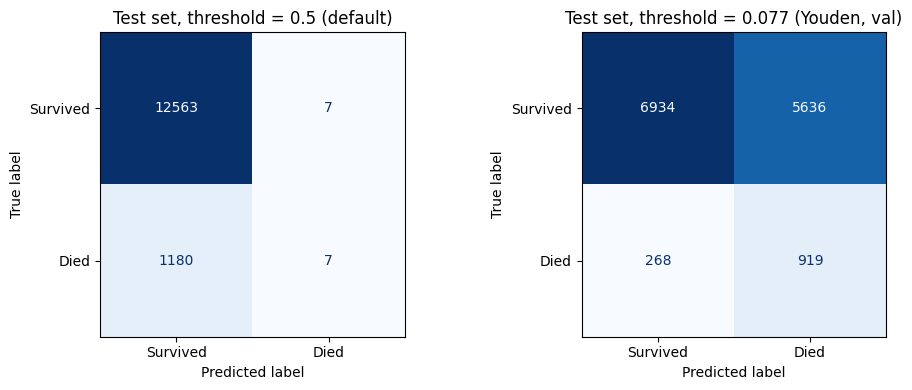

Test AUROC (threshold-free): 0.7287
Test death rate: 0.086  ->  'predict everyone survives' accuracy = 0.914



,accuracy,balanced_accuracy,precision (PPV),recall / sensitivity (TPR),specificity (TNR),F1,NPV,TP,FP,FN,TN
threshold,,,,,,,,,,,
0.5 (default),0.9137,0.5027,0.5000,0.0059,0.9994,0.0117,0.9141,7,7,1180,12563
"0.077 (Youden, val)",0.5708,0.6629,0.1402,0.7742,0.5516,0.2374,0.9628,919,5636,268,6934



Classification report @ Youden threshold:
              precision    recall  f1-score   support

    Survived     0.9628    0.5516    0.7014     12570
        Died     0.1402    0.7742    0.2374      1187

    accuracy                         0.5708     13757
   macro avg     0.5515    0.6629    0.4694     13757
weighted avg     0.8918    0.5708    0.6614     13757



In [23]:
# ---- Classification report & confusion matrix (raw XGBoost, test set) ----
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, classification_report)

p_va_raw_cm = model.predict_proba(X_va)[:, 1]
p_te_raw_cm = model.predict_proba(X_te)[:, 1]

# Two thresholds: the default 0.5, and Youden's J chosen on validation (better for an ~8% death rate)
fpr_v, tpr_v, thr_v = roc_curve(y_va, p_va_raw_cm)
thr_youden_raw = float(thr_v[np.argmax(tpr_v - fpr_v)])
thresholds_cm = {"0.5 (default)": 0.5, f"{thr_youden_raw:.3f} (Youden, val)": thr_youden_raw}

rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, t) in zip(axes, thresholds_cm.items()):
    yhat = (p_te_raw_cm >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, yhat, labels=[0, 1]).ravel()
    rows.append({
        "threshold": name,
        "accuracy": accuracy_score(y_te, yhat),
        "balanced_accuracy": balanced_accuracy_score(y_te, yhat),
        "precision (PPV)": precision_score(y_te, yhat, zero_division=0),
        "recall / sensitivity (TPR)": recall_score(y_te, yhat, zero_division=0),
        "specificity (TNR)": tn / (tn + fp) if (tn + fp) else np.nan,
        "F1": f1_score(y_te, yhat, zero_division=0),
        "NPV": tn / (tn + fn) if (tn + fn) else np.nan,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    })
    ConfusionMatrixDisplay(confusion_matrix(y_te, yhat, labels=[0, 1]),
                           display_labels=["Survived", "Died"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"Test set, threshold = {name}")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/confusion_matrix_raw.png", dpi=150); plt.show()

print(f"Test AUROC (threshold-free): {roc_auc_score(y_te, p_te_raw_cm):.4f}")
print(f"Test death rate: {y_te.mean():.3f}  ->  'predict everyone survives' accuracy = {1 - y_te.mean():.3f}\n")
display(pd.DataFrame(rows).set_index("threshold").round(4))

print("\nClassification report @ Youden threshold:")
print(classification_report(y_te, (p_te_raw_cm >= thr_youden_raw).astype(int),
                            target_names=["Survived", "Died"], digits=4))

## 7. Calibration and decision threshold
Platt scaling on the raw logit, fitted on the validation split. The **decision threshold** for the binary flag maximises Youden's J (TPR − FPR) on validation; it is the "before" setting of the fairness audit.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             log_loss, roc_curve)

raw_va = model.predict_proba(X_va)[:, 1]
platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(raw_va).reshape(-1, 1), y_va)
CAL_A, CAL_B = float(platt.coef_[0, 0]), float(platt.intercept_[0])
clf = CalibratedXGB(model, CAL_A, CAL_B).fit()
print(f"Platt: p = sigmoid({CAL_A:.4f} * logit(p_raw) + {CAL_B:.4f})")

p_va = clf.predict_proba(X_va)[:, 1]
fpr, tpr, thr = roc_curve(y_va, p_va)
DECISION_THRESHOLD = float(thr[np.argmax(tpr - fpr)])
print(f"decision threshold (Youden J on val): {DECISION_THRESHOLD:.4f}")

Platt: p = sigmoid(0.9961 * logit(p_raw) + -0.0224)
decision threshold (Youden J on val): 0.0758


In [12]:
BASE_RATE_TRAIN = float(y_tr.mean())

def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    return float(sum(abs(p[idx == b].mean() - y[idx == b].mean()) * (idx == b).mean()
                     for b in range(bins) if (idx == b).any()))

def evaluate(y, p):
    brier = brier_score_loss(y, p)
    brier_ref = brier_score_loss(y, np.full_like(p, BASE_RATE_TRAIN, dtype=float))  # "always predict train base rate"
    return dict(n=int(len(y)), prevalence=float(y.mean()),
                auroc=float(roc_auc_score(y, p)), auprc=float(average_precision_score(y, p)),
                brier=float(brier), brier_reference=float(brier_ref),
                brier_skill_score=float(1 - brier / brier_ref),
                log_loss=float(log_loss(y, np.clip(p, 1e-6, 1 - 1e-6))), ece=ece(y, p))

p_te_raw = clf.raw_proba(X_te)
p_te     = clf.predict_proba(X_te)[:, 1]
results = {
    "val":  {"raw": evaluate(y_va, raw_va), "calibrated": evaluate(y_va, p_va)},
    "test": {"raw": evaluate(y_te, p_te_raw), "calibrated": evaluate(y_te, p_te)},
}
display(pd.DataFrame({f"{s}/{k}": v for s in results for k, v in results[s].items()}).T.round(4))
print(f"\nBrier skill score (test, calibrated) = {results['test']['calibrated']['brier_skill_score']:.4f}")

,n,prevalence,auroc,auprc,brier,brier_reference,brier_skill_score,log_loss,ece
val/raw,13757.0,0.0863,0.7261,0.1977,0.0744,0.0788,0.0559,0.2671,0.0017
val/calibrated,13757.0,0.0863,0.7261,0.1977,0.0744,0.0788,0.0559,0.2671,0.0020
test/raw,13757.0,0.0863,0.7287,0.2010,0.0743,0.0788,0.0576,0.2662,0.0035
test/calibrated,13757.0,0.0863,0.7287,0.2010,0.0743,0.0788,0.0576,0.2662,0.0027



Brier skill score (test, calibrated) = 0.0576


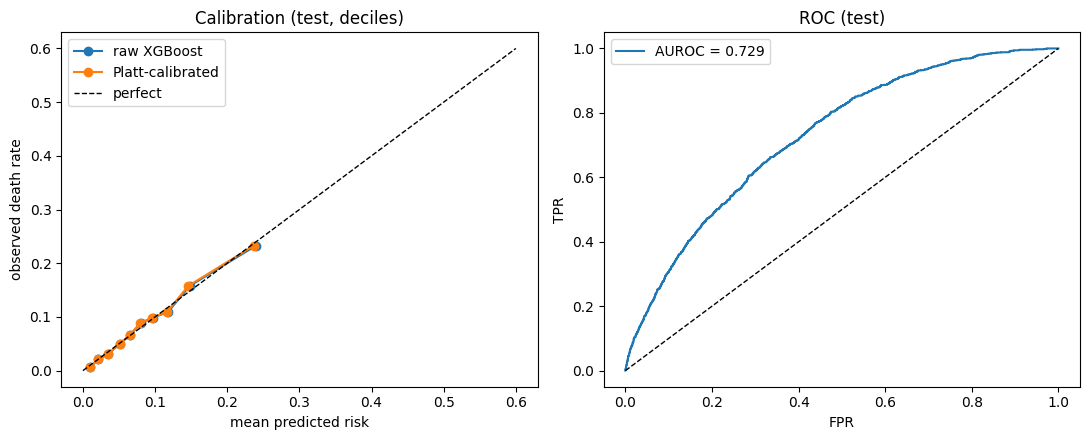

In [13]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for p, lab in [(p_te_raw, "raw XGBoost"), (p_te, "Platt-calibrated")]:
    fr, mp = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[0].plot(mp, fr, marker="o", label=lab)
axes[0].plot([0, 0.6], [0, 0.6], "k--", lw=1, label="perfect")
axes[0].set(xlabel="mean predicted risk", ylabel="observed death rate", title="Calibration (test, deciles)")
axes[0].legend()

f, t, _ = roc_curve(y_te, p_te)
axes[1].plot(f, t, label=f"AUROC = {results['test']['calibrated']['auroc']:.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set(xlabel="FPR", ylabel="TPR", title="ROC (test)")
axes[1].legend()
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/calibration_roc.png", dpi=150); plt.show()

## 8. SHAP explanations
Computed with XGBoost's native TreeSHAP (`pred_contribs=True`), which avoids version issues with the `shap` package. Values are in **log-odds of the raw model**; Platt scaling is monotone, so the ranking and direction carry over to `p_base`. One-hot columns are summed back to their source feature.

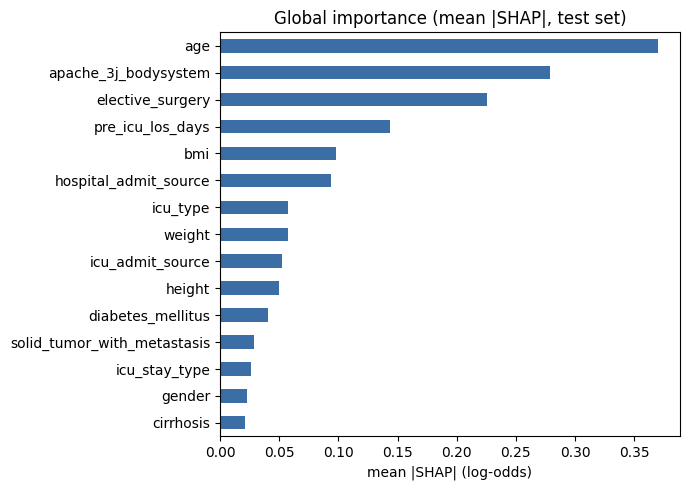

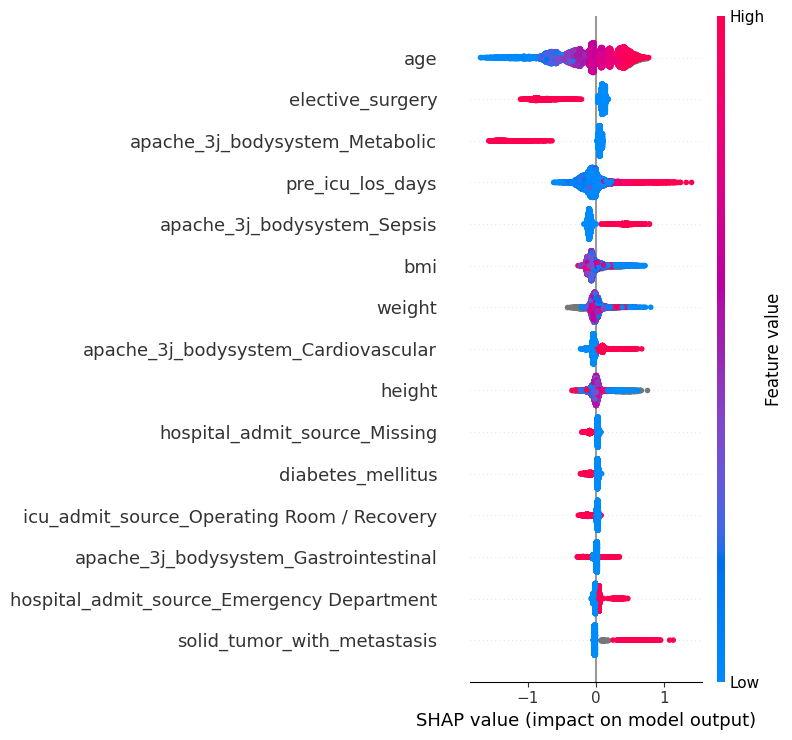

In [14]:
contrib_te = model.get_booster().predict(xgb.DMatrix(X_te), pred_contribs=True)
shap_te = pd.DataFrame(contrib_te[:, :-1], columns=ENC_FEATURES, index=X_te.index)

imp_enc = shap_te.abs().mean().sort_values(ascending=False).rename("mean_abs_shap")
imp_orig = (shap_te.T.groupby(pd.Series(encoded_to_original)).sum().T   # sum one-hot parts per patient
            .abs().mean().sort_values(ascending=False).rename("mean_abs_shap"))

fig, ax = plt.subplots(figsize=(7, 5))
imp_orig.head(15)[::-1].plot.barh(ax=ax, color="#3b6ea5")
ax.set(title="Global importance (mean |SHAP|, test set)", xlabel="mean |SHAP| (log-odds)")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/shap_global_importance.png", dpi=150); plt.show()

try:
    import shap
    shap.summary_plot(shap_te.values, X_te, max_display=15, show=False)
    plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/shap_beeswarm.png", dpi=150); plt.show()
except Exception as e:
    print("beeswarm skipped:", e)

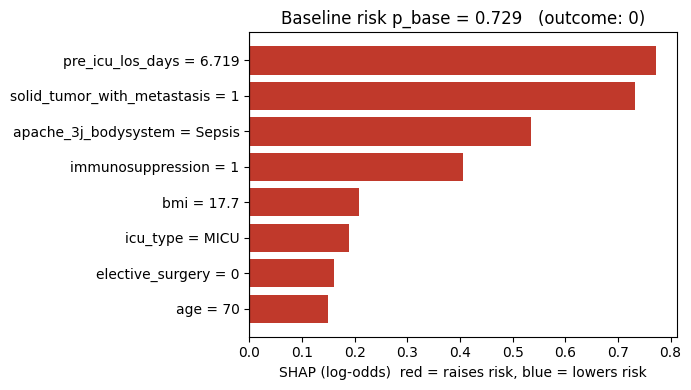

In [15]:
# Single-patient explanation (this is the bar chart the report in Notebook 4 will show)
def patient_bar(row_idx, top_k=8, save=None):
    contrib = shap_te.loc[row_idx]
    agg = contrib.groupby(pd.Series(encoded_to_original)).sum()
    agg = agg.reindex(agg.abs().sort_values(ascending=False).index).head(top_k)[::-1]
    raw = prepare_frame(te.loc[[row_idx]]).iloc[0]
    fmt = lambda v: f"{v:.4g}" if isinstance(v, (int, float, np.floating)) and not pd.isna(v) else str(v)
    labels = [f"{f} = {fmt(raw[f])}" for f in agg.index]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh(labels, agg.values, color=["#c0392b" if v > 0 else "#2e86c1" for v in agg.values])
    ax.axvline(0, color="k", lw=0.8)
    ax.set(xlabel="SHAP (log-odds)  red = raises risk, blue = lowers risk",
           title=f"Baseline risk p_base = {p_te[te.index.get_loc(row_idx)]:.3f}   (outcome: {te.loc[row_idx, TARGET]})")
    plt.tight_layout()
    if save: plt.savefig(save, dpi=150)
    plt.show()

example_idx = te.index[np.argmax(p_te)]   # highest-risk test patient
patient_bar(example_idx, save=f"{PLOT_DIR}/shap_example_patient.png")

## 9. Fairness audit — before post-processing
Equalized odds asks for **equal TPR and equal FPR across groups**. We measure it for the single global threshold, by ethnicity (primary), sex and age band.
Groups with fewer than `MIN_DEATHS_REPORT` test deaths are flagged `low_support`; their TPR is too noisy to judge and they are excluded from the headline gap.

In [16]:
# Audit groups used by the post-processor: small groups (few deaths in validation) merged into "Other/Unknown"
val_deaths = va.groupby("ethnicity_raw")[TARGET].sum()
AUDIT_GROUP_MAP = {g: (g if (val_deaths.get(g, 0) >= MIN_DEATHS_FOR_EO_GROUP and g not in ("Unknown", "Other/Unknown"))
                       else "Other/Unknown") for g in df["ethnicity_raw"].unique()}
print("audit group map:", AUDIT_GROUP_MAP)
g_va = map_audit_groups(va[PROTECTED], AUDIT_GROUP_MAP)
g_te = map_audit_groups(te[PROTECTED], AUDIT_GROUP_MAP)

def group_metrics(y, prob, yhat, groups, setting, attribute):
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(prob), "yhat": np.asarray(yhat), "g": np.asarray(groups)})
    rows = []
    for g, s in d.groupby("g"):
        pos, neg = s.y == 1, s.y == 0
        rows.append(dict(attribute=attribute, setting=setting, group=g, n=len(s), n_deaths=int(pos.sum()),
                         death_rate=s.y.mean(), mean_p_base=s.p.mean(),
                         TPR=s.yhat[pos].mean() if pos.any() else np.nan,
                         FPR=s.yhat[neg].mean() if neg.any() else np.nan,
                         flag_rate=s.yhat.mean(),
                         AUROC=roc_auc_score(s.y, s.p) if s.y.nunique() == 2 else np.nan,
                         Brier=brier_score_loss(s.y, s.p)))
    t = pd.DataFrame(rows)
    t["low_support"] = t["n_deaths"] < MIN_DEATHS_REPORT
    return t

def eo_gaps(t):
    r = t[~t["low_support"]]
    tpr_gap = float(r.TPR.max() - r.TPR.min()) if len(r) > 1 else np.nan
    fpr_gap = float(r.FPR.max() - r.FPR.min()) if len(r) > 1 else np.nan
    return dict(TPR_gap=tpr_gap, FPR_gap=fpr_gap, equalized_odds_difference=float(np.nanmax([tpr_gap, fpr_gap])),
                groups_used=list(r.group))

yhat_before = (p_te >= DECISION_THRESHOLD).astype(int)
audit = {
    "ethnicity (raw)":    group_metrics(y_te, p_te, yhat_before, te["ethnicity_raw"], "before", "ethnicity_raw"),
    "ethnicity (audit groups)": group_metrics(y_te, p_te, yhat_before, g_te, "before", "ethnicity_audit"),
    "sex":                group_metrics(y_te, p_te, yhat_before, te["sex_group"], "before", "sex"),
    "age band":           group_metrics(y_te, p_te, yhat_before, te["age_band"], "before", "age_band"),
}
for name, t in audit.items():
    print(f"\n=== {name} ===  gaps: { {k: (round(v, 4) if isinstance(v, float) else v) for k, v in eo_gaps(t).items()} }")
    display(t.drop(columns=["attribute", "setting"]).round(3))

audit group map: {'Caucasian': 'Caucasian', 'Unknown': 'Other/Unknown', 'Hispanic': 'Hispanic', 'African American': 'African American', 'Asian': 'Other/Unknown', 'Native American': 'Other/Unknown', 'Other/Unknown': 'Other/Unknown'}

=== ethnicity (raw) ===  gaps: {'TPR_gap': 0.1741, 'FPR_gap': 0.1239, 'equalized_odds_difference': 0.1741, 'groups_used': ['African American', 'Caucasian', 'Hispanic', 'Other/Unknown']}


,group,n,n_deaths,death_rate,mean_p_base,TPR,FPR,flag_rate,AUROC,Brier,low_support
0,African American,1433,113,0.079,0.076,0.673,0.358,0.382,0.729,0.067,False
1,Asian,169,14,0.083,0.091,0.643,0.497,0.509,0.672,0.074,True
2,Caucasian,10602,925,0.087,0.087,0.797,0.465,0.494,0.727,0.075,False
3,Hispanic,569,56,0.098,0.089,0.732,0.481,0.506,0.736,0.084,False
4,Native American,118,10,0.085,0.081,0.900,0.370,0.415,0.841,0.065,True
5,Other/Unknown,656,53,0.081,0.083,0.623,0.378,0.398,0.712,0.072,False
6,Unknown,210,16,0.076,0.082,0.875,0.392,0.429,0.797,0.061,True



=== ethnicity (audit groups) ===  gaps: {'TPR_gap': 0.1242, 'FPR_gap': 0.1239, 'equalized_odds_difference': 0.1242, 'groups_used': ['African American', 'Caucasian', 'Hispanic', 'Other/Unknown']}


,group,n,n_deaths,death_rate,mean_p_base,TPR,FPR,flag_rate,AUROC,Brier,low_support
0,African American,1433,113,0.079,0.076,0.673,0.358,0.382,0.729,0.067,False
1,Caucasian,10602,925,0.087,0.087,0.797,0.465,0.494,0.727,0.075,False
2,Hispanic,569,56,0.098,0.089,0.732,0.481,0.506,0.736,0.084,False
3,Other/Unknown,1153,93,0.081,0.084,0.699,0.397,0.422,0.735,0.069,False



=== sex ===  gaps: {'TPR_gap': 0.009, 'FPR_gap': 0.0456, 'equalized_odds_difference': 0.0456, 'groups_used': ['F', 'M']}


,group,n,n_deaths,death_rate,mean_p_base,TPR,FPR,flag_rate,AUROC,Brier,low_support
0,F,6277,561,0.089,0.088,0.779,0.473,0.501,0.712,0.077,False
1,M,7478,626,0.084,0.084,0.770,0.428,0.456,0.743,0.072,False
2,Unknown,2,0,0.000,0.090,NaN,0.500,0.500,NaN,0.015,True



=== age band ===  gaps: {'TPR_gap': 0.5275, 'FPR_gap': 0.7575, 'equalized_odds_difference': 0.7575, 'groups_used': ['40-59', '60-74', '75+', '<40', 'Unknown']}


,group,n,n_deaths,death_rate,mean_p_base,TPR,FPR,flag_rate,AUROC,Brier,low_support
0,40-59,3702,204,0.055,0.057,0.490,0.193,0.210,0.734,0.049,False
1,60-74,4522,411,0.091,0.087,0.764,0.505,0.528,0.694,0.079,False
2,75+,3497,439,0.126,0.124,0.925,0.769,0.788,0.669,0.105,False
3,<40,1413,52,0.037,0.033,0.423,0.065,0.079,0.823,0.032,False
4,Unknown,623,81,0.130,0.150,0.951,0.823,0.839,0.648,0.113,False


## 10. Equalized-odds post-processing (binary flag only)
`ThresholdOptimizer` picks group-specific (possibly randomised) thresholds on validation so that TPR and FPR match across groups, maximising balanced accuracy.
It changes **only the binary flag**. `p_base`, AUROC and Brier per group are unchanged — that is the "keep the unconstrained probability" decision.

Note: post-processing needs group membership at decision time. Ethnicity still never enters the probability model.

In [17]:
from fairlearn.postprocessing import ThresholdOptimizer

eo = ThresholdOptimizer(estimator=clf, constraints="equalized_odds", objective="balanced_accuracy_score",
                        prefit=True, predict_method="predict_proba")
eo.fit(X_va, y_va, sensitive_features=g_va)
yhat_after = eo.predict(X_te, sensitive_features=g_te, random_state=SEED)

before = audit["ethnicity (audit groups)"]
after  = group_metrics(y_te, p_te, yhat_after, g_te, "after", "ethnicity_audit")
gaps_before, gaps_after = eo_gaps(before), eo_gaps(after)

from sklearn.metrics import balanced_accuracy_score, recall_score
overall = pd.DataFrame({
    "before": {"balanced_acc": balanced_accuracy_score(y_te, yhat_before), "TPR": recall_score(y_te, yhat_before),
               "FPR": yhat_before[y_te == 0].mean(), **{k: v for k, v in gaps_before.items() if k != "groups_used"}},
    "after":  {"balanced_acc": balanced_accuracy_score(y_te, yhat_after), "TPR": recall_score(y_te, yhat_after),
               "FPR": yhat_after[y_te == 0].mean(), **{k: v for k, v in gaps_after.items() if k != "groups_used"}},
})
display(overall.round(4))
display(pd.concat([before, after])[["setting", "group", "n", "n_deaths", "TPR", "FPR", "flag_rate", "low_support"]].round(3))

,before,after
balanced_acc,0.6629,0.6455
TPR,0.7742,0.5299
FPR,0.4484,0.2388
TPR_gap,0.1242,0.0662
FPR_gap,0.1239,0.0302
equalized_odds_difference,0.1242,0.0662


,setting,group,n,n_deaths,TPR,FPR,flag_rate,low_support
0,before,African American,1433,113,0.673,0.358,0.382,False
1,before,Caucasian,10602,925,0.797,0.465,0.494,False
2,before,Hispanic,569,56,0.732,0.481,0.506,False
3,before,Other/Unknown,1153,93,0.699,0.397,0.422,False
0,after,African American,1433,113,0.584,0.235,0.262,False
1,after,Caucasian,10602,925,0.521,0.236,0.260,False
2,after,Hispanic,569,56,0.518,0.257,0.283,False
3,after,Other/Unknown,1153,93,0.559,0.265,0.289,False


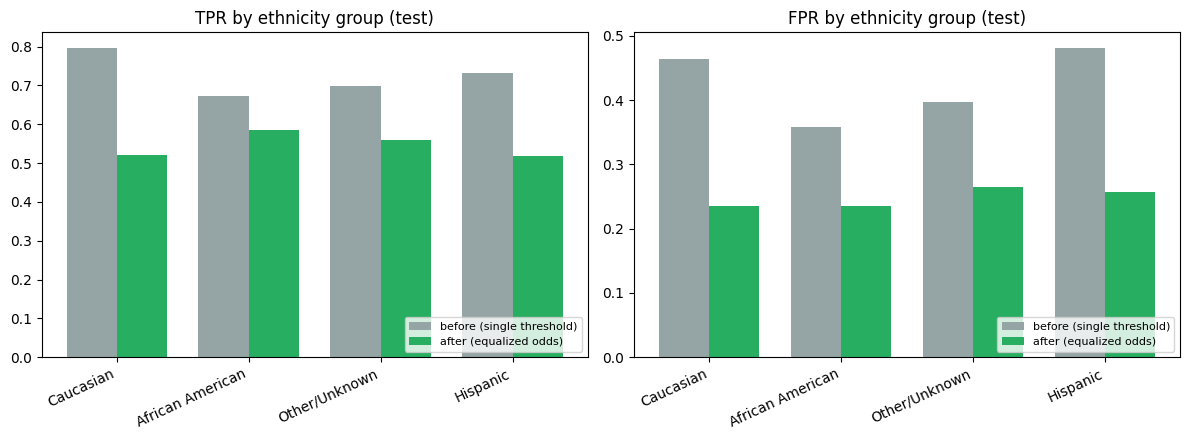

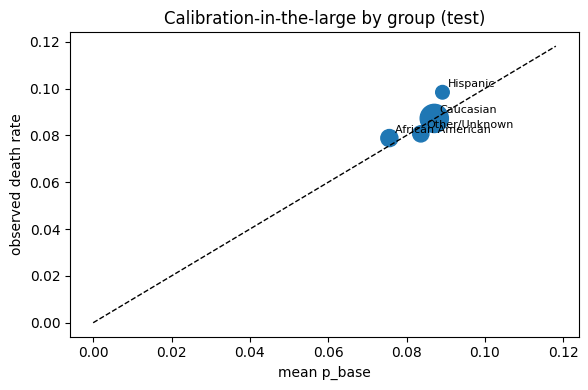

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
groups_sorted = before.sort_values("n", ascending=False)["group"].tolist()
w = 0.38
x = np.arange(len(groups_sorted))
for ax, metric in zip(axes, ["TPR", "FPR"]):
    b = before.set_index("group").loc[groups_sorted, metric]
    a = after.set_index("group").loc[groups_sorted, metric]
    ax.bar(x - w/2, b, w, label="before (single threshold)", color="#95a5a6")
    ax.bar(x + w/2, a, w, label="after (equalized odds)", color="#27ae60")
    ax.set_xticks(x); ax.set_xticklabels(groups_sorted, rotation=25, ha="right")
    ax.set_title(f"{metric} by ethnicity group (test)")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/fairness_tpr_fpr.png", dpi=150); plt.show()

# calibration by group: equalized odds and within-group calibration cannot both hold in general -> report both
fig, ax = plt.subplots(figsize=(6, 4))
cal_tab = before.set_index("group").loc[groups_sorted]
ax.scatter(cal_tab["mean_p_base"], cal_tab["death_rate"], s=np.sqrt(cal_tab["n"]) * 4)
for g, r in cal_tab.iterrows():
    ax.annotate(g, (r.mean_p_base, r.death_rate), fontsize=8, xytext=(4, 4), textcoords="offset points")
lim = max(cal_tab[["mean_p_base", "death_rate"]].max()) * 1.2
ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set(xlabel="mean p_base", ylabel="observed death rate", title="Calibration-in-the-large by group (test)")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/fairness_group_calibration.png", dpi=150); plt.show()

## 11. Proxy check
Removing ethnicity from the inputs does not guarantee the model cannot infer it. We train a small model to predict the audit group from the **same background features**; a high AUROC means proxies exist. We then check whether the strongest proxies are also important for mortality.

In [19]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder().fit(np.concatenate([map_audit_groups(tr[PROTECTED], AUDIT_GROUP_MAP), g_te]))
gp_tr = le.transform(map_audit_groups(tr[PROTECTED], AUDIT_GROUP_MAP))
gp_te = le.transform(g_te)

proxy = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                          colsample_bytree=0.8, tree_method="hist", random_state=SEED, n_jobs=-1)
proxy.fit(X_tr, gp_tr)
proba_g = proxy.predict_proba(X_te)
if len(le.classes_) > 2:
    proxy_auc = roc_auc_score(gp_te, proba_g, multi_class="ovr", average="macro")
else:
    proxy_auc = roc_auc_score(gp_te, proba_g[:, 1])
print(f"Ethnicity recoverable from background features: macro AUROC = {proxy_auc:.3f}  (0.5 = no proxy signal)")

proxy_imp = pd.Series(proxy.feature_importances_, index=ENC_FEATURES)
proxy_imp = proxy_imp.groupby(pd.Series(encoded_to_original)).sum().sort_values(ascending=False)
mort_rank = imp_orig.rank(ascending=False)
proxy_table = pd.DataFrame({"proxy_importance": proxy_imp.head(8),
                            "mortality_shap_rank": mort_rank.reindex(proxy_imp.head(8).index)})
display(proxy_table.round(3))

Ethnicity recoverable from background features: macro AUROC = 0.725  (0.5 = no proxy signal)


,proxy_importance,mortality_shap_rank
icu_type,0.205,7.0
hospital_admit_source,0.186,6.0
apache_3j_bodysystem,0.135,2.0
icu_stay_type,0.085,13.0
icu_admit_source,0.085,9.0
gender,0.080,14.0
age,0.028,1.0
height,0.026,10.0


## 12. Save artifacts

In [20]:
import joblib, sklearn, fairlearn

joblib.dump(preproc, f"{OUT_DIR}/preprocessor.joblib")
model.save_model(f"{OUT_DIR}/xgb_model.json")
json.dump({"type": "platt_on_logit", "formula": "p = sigmoid(a*logit(p_raw)+b)", "a": CAL_A, "b": CAL_B},
          open(f"{OUT_DIR}/calibrator.json", "w"), indent=2)
joblib.dump(eo, f"{OUT_DIR}/eq_odds_postprocessor.joblib")
json.dump(AUDIT_GROUP_MAP, open(f"{OUT_DIR}/audit_group_map.json", "w"), indent=2)

json.dump({"target": TARGET, "id_col": ID_COL, "protected_audit_only": PROTECTED,
           "numeric": NUMERIC, "binary": BINARY, "categorical": CATEGORICAL, "features": FEATURES,
           "encoded_features": ENC_FEATURES, "encoded_to_original": encoded_to_original,
           "excluded_on_purpose": EXCLUDED_ON_PURPOSE},
          open(f"{OUT_DIR}/feature_config.json", "w"), indent=2)

metrics = {
    "model": "XGBoost (background features) + Platt calibration",
    "base_rate_train": BASE_RATE_TRAIN,
    "decision_threshold": DECISION_THRESHOLD,
    "best_iteration": int(model.best_iteration),
    "xgb_params": {k: v for k, v in XGB_PARAMS.items()},
    "val": results["val"], "test": results["test"],
    "reliability_weight_note": "brier_skill_score = 1 - Brier/Brier(train base rate); use test/calibrated value",
    "fairness": {"attribute": "ethnicity (audit groups)", "constraint": "equalized_odds (binary flag only)",
                 "before": gaps_before, "after": gaps_after,
                 "overall_before_after": overall.to_dict(),
                 "proxy_macro_auroc": float(proxy_auc)},
    "split": {"seed": SEED, "val_frac": VAL_FRAC, "test_frac": TEST_FRAC,
              "n_train": int(len(tr)), "n_val": int(len(va)), "n_test": int(len(te))},
    "versions": {"python": platform.python_version(), "xgboost": xgb.__version__, "sklearn": sklearn.__version__,
                 "fairlearn": fairlearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
json.dump(metrics, open(f"{OUT_DIR}/metrics.json", "w"), indent=2, default=float)

pd.concat(list(audit.values()) + [after]).to_csv(f"{OUT_DIR}/fairness_audit.csv", index=False)
pd.DataFrame({"mean_abs_shap": imp_orig}).to_csv(f"{OUT_DIR}/shap_importance_original.csv")
pd.DataFrame({"mean_abs_shap": imp_enc}).to_csv(f"{OUT_DIR}/shap_importance_encoded.csv")
proxy_table.to_csv(f"{OUT_DIR}/proxy_check.csv")

# test-set patients for the Notebook-4 demo (raw background features + audit attributes + outputs)
demo = te[[ID_COL] + FEATURES + [PROTECTED, "sex_group", "age_band", TARGET]].copy()
demo["p_base"] = p_te
demo["flag_single_threshold"] = yhat_before
demo["flag_equalized_odds"] = yhat_after
demo.to_csv(f"{OUT_DIR}/test_patients.csv", index=False)
print("saved.")

saved.


## 13. Reload check and packaging

In [21]:
# Reload everything from disk exactly as Notebook 4 will, and confirm identical predictions
importlib.reload(xgb_inference)
from xgb_inference import BaselineRiskModel
base = BaselineRiskModel(OUT_DIR)

p_reload = base.predict_base(te)
assert np.allclose(p_reload, p_te, atol=1e-6), "reloaded predictions differ!"
flag_reload = base.fair_decision(te, random_state=SEED)
print("reload OK | max |diff| =", float(np.abs(p_reload - p_te).max()),
      "| EO flag agreement =", float((flag_reload == yhat_after).mean()))

top, expected = base.explain(te.loc[[example_idx]])
print(f"\nexample patient: p_base = {base.predict_base(te.loc[[example_idx]])[0]:.3f}, expected log-odds = {expected:.3f}")
display(top.round(4))

reload OK | max |diff| = 0.0 | EO flag agreement = 1.0

example patient: p_base = 0.729, expected log-odds = -2.366


,feature,shap,value
0,pre_icu_los_days,0.7727,6.71875
1,solid_tumor_with_metastasis,0.7329,1.0
2,apache_3j_bodysystem,0.5348,Sepsis
3,immunosuppression,0.4064,1.0
4,bmi,0.2087,17.697959
5,icu_type,0.1891,MICU
6,elective_surgery,0.1617,0
7,age,0.1487,70.0


In [22]:
zip_path = shutil.make_archive(os.path.join(WORK_DIR, "artifacts_xgboost"), "zip", OUT_DIR)
print("zip:", zip_path, f"({os.path.getsize(zip_path)/1e6:.2f} MB)\n")
for root, _, files in os.walk(OUT_DIR):
    for f in sorted(files):
        p = os.path.join(root, f)
        print(f"{os.path.relpath(p, OUT_DIR):45s} {os.path.getsize(p)/1e3:9.1f} KB")

zip: /kaggle/working/artifacts_xgboost.zip (1.62 MB)

audit_group_map.json                                0.2 KB
calibrator.json                                     0.1 KB
eq_odds_postprocessor.joblib                     1195.3 KB
fairness_audit.csv                                  4.1 KB
feature_config.json                                 6.6 KB
metrics.json                                        3.7 KB
preprocessor.joblib                                 6.3 KB
proxy_check.csv                                     0.3 KB
shap_importance_encoded.csv                         2.2 KB
shap_importance_original.csv                        0.5 KB
test_patients.csv                                2566.8 KB
xgb_inference.py                                    6.4 KB
xgb_model.json                                   1211.6 KB
plots/calibration_roc.png                          91.3 KB
plots/fairness_group_calibration.png               52.2 KB
plots/fairness_tpr_fpr.png                         62.8 KB
pl

### Summary for the report
Values that later notebooks use:
- `metrics.json → base_rate_train` and `test.calibrated.brier_skill_score`
- `p_base` for any patient via `BaselineRiskModel.predict_base`
- `explain()` gives the SHAP bar chart data for the per-patient report

**Limitations to state:** the binary equalized-odds flag uses group membership at decision time (standard for post-processing); small ethnicity groups are merged for the post-processor and flagged low-support in the audit; fairness can only be audited on this model, since the time-series and imaging datasets have no ethnicity field.